Sapphire IQ | Supermarket Sales Analysis
Internship project: Data Analytics
Dataset: Supermarket Sales Analysis Dashboard (V.2)
Tools: Python, Pandas, NumPy, Matplotlib, Seaborn, Jupyter Notebook
Project purpose
Analyse supermarket sales data and answer the four objectives in the Sapphire IQ project brief:
1. Overall Sales Performance — total sales revenue, average sales per record, and average product visibility.
2. Product Category and Sales Comparison — top-four category contribution, highest/lowest categories, and outlet-type sales.
3. Outlet Performance and Sales Relationships — Low Fat vs Regular sales by outlet, visibility-sales relationship, and category contribution by outlet type.
4. Statistical Analysis of Sales — mean, median, minimum, maximum, variation, unusual sales records, and average sales by category, outlet type, and location.

## 1. Import libraries and load the workbook



In [ ]:
from pathlib import Path
import warnings

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", lambda x: f"{x:,.4f}")

sns.set_theme(style="whitegrid", context="notebook")

file_path = Path("Supermarket Sales Analysis Dashboard (V.2) (1).xlsx")

if not file_path.exists():
    # Fallback for the uploaded-file location used in this working environment
    file_path = Path("/mnt/data/Supermarket Sales Analysis Dashboard (V.2) (1).xlsx")

if not file_path.exists():
    raise FileNotFoundError(
        "Excel workbook not found. Put it beside this notebook or update file_path."
    )

df_raw = pd.read_excel(file_path, sheet_name="BlinkIT Grocery Data")
print(f"Loaded: {file_path.name}")
print(f"Dataset shape: {df_raw.shape[0]:,} rows x {df_raw.shape[1]} columns")
display(df_raw.head())

Loaded: Supermarket Sales Analysis Dashboard (V.2) (1).xlsx
Dataset shape: 8,523 rows x 12 columns


,Item Fat Content,Item Identifier,Item Type,Outlet Establishment Year,Outlet Identifier,Outlet Location Type,Outlet Size,Outlet Type,Item Visibility,Item Weight,Sales,Rating
0,Regular,FDX32,Fruits and Vegetables,2012,OUT049,Tier 1,Medium,Supermarket Type1,0.1000,15.1000,145.4786,5.0000
1,Low Fat,NCB42,Health and Hygiene,2022,OUT018,Tier 3,Medium,Supermarket Type2,0.0086,11.8000,115.3492,5.0000
2,Regular,FDR28,Frozen Foods,2016,OUT046,Tier 1,Small,Supermarket Type1,0.0259,13.8500,165.0210,5.0000
3,Regular,FDL50,Canned,2014,OUT013,Tier 3,High,Supermarket Type1,0.0423,12.1500,126.5046,5.0000
4,Low Fat,DRI25,Soft Drinks,2015,OUT045,Tier 2,Small,Supermarket Type1,0.0340,19.6000,55.1614,5.0000


## 2. Analyse the dataset EDA

 the field names, data types, missing values, duplicates

In [ ]:
print("Column names:")
print(df_raw.columns.tolist())

print("\nData types and non-null counts:")
df_raw.info()

print("\nMissing values:")
display(df_raw.isna().sum().to_frame("Missing values"))

print("\nDuplicate rows:", df_raw.duplicated().sum())

print("\nNumeric summary:")
display(df_raw.describe().T)

Column names:
['Item Fat Content', 'Item Identifier', 'Item Type', 'Outlet Establishment Year', 'Outlet Identifier', 'Outlet Location Type', 'Outlet Size', 'Outlet Type', 'Item Visibility', 'Item Weight', 'Sales', 'Rating']

Data types and non-null counts:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8523 entries, 0 to 8522
Data columns (total 12 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   Item Fat Content           8523 non-null   object 
 1   Item Identifier            8523 non-null   object 
 2   Item Type                  8523 non-null   object 
 3   Outlet Establishment Year  8523 non-null   int64  
 4   Outlet Identifier          8523 non-null   object 
 5   Outlet Location Type       8523 non-null   object 
 6   Outlet Size                8523 non-null   object 
 7   Outlet Type                8523 non-null   object 
 8   Item Visibility            8523 non-null   float64
 9   Item Weight    

,Missing values
Item Fat Content,0
Item Identifier,0
Item Type,0
Outlet Establishment Year,0
Outlet Identifier,0
Outlet Location Type,0
Outlet Size,0
Outlet Type,0
Item Visibility,0
Item Weight,1463



Duplicate rows: 0

Numeric summary:


,count,mean,std,min,25%,50%,75%,max
Outlet Establishment Year,"8,523.0000","2,016.4505",3.1894,"2,011.0000","2,014.0000","2,016.0000","2,018.0000","2,022.0000"
Item Visibility,"8,523.0000",0.0661,0.0516,0.0000,0.0270,0.0539,0.0946,0.3284
Item Weight,"7,060.0000",12.8576,4.6435,4.5550,8.7737,12.6000,16.8500,21.3500
Sales,"8,523.0000",140.9928,62.2751,31.2900,93.8265,143.0128,185.6437,266.8884
Rating,"8,523.0000",3.9659,0.6057,1.0000,4.0000,4.0000,4.2000,5.0000


## 3. Data cleaning and preparation



In [ ]:
df = df_raw.copy()

# Standardise inconsistent category labels
df["Item Fat Content"] = (
    df["Item Fat Content"]
    .astype("string")
    .str.strip()
    .str.lower()
    .replace({
        "lf": "low fat",
        "low fat": "low fat",
        "reg": "regular",
        "regular": "regular"
    })
    .str.title()
)

# Impute missing item weights with the overall median
missing_weight_before = df["Item Weight"].isna().sum()
weight_median = df["Item Weight"].median()
df["Item Weight"] = df["Item Weight"].fillna(weight_median)

# Basic validation
print("Missing Item Weight before cleaning:", missing_weight_before)
print("Median used for Item Weight imputation:", round(weight_median, 3))
print("Missing values after cleaning:", int(df.isna().sum().sum()))
print("Duplicate rows:", int(df.duplicated().sum()))
print("\nStandardised fat-content labels:")
display(df["Item Fat Content"].value_counts())

Missing Item Weight before cleaning: 1463
Median used for Item Weight imputation: 12.6
Missing values after cleaning: 0
Duplicate rows: 0

Standardised fat-content labels:


Item Fat Content
Low Fat    5517
Regular    3006
Name: count, dtype: Int64

## 4. Objective 1 — Overall Sales Performance

 Business questions
1. What is the total sales revenue?
2. What is the average sales value per record?
3. What is the average visibility of products?



In [ ]:
total_sales = df["Sales"].sum()
average_sales = df["Sales"].mean()
average_visibility = df["Item Visibility"].mean()

objective1_kpis = pd.DataFrame({
    "Business Metric": [
        "Total sales revenue",
        "Average sales per record",
        "Average item visibility"
    ],
    "Value": [
        total_sales,
        average_sales,
        average_visibility
    ]
})

display(objective1_kpis.style.format({"Value": "{:,.4f}"}))

print(f"Total sales revenue: {total_sales:,.2f}")
print(f"Average sales per record: {average_sales:,.2f}")
print(f"Average item visibility: {average_visibility:.4f} ({average_visibility:.2%})")

,Business Metric,Value
0,Total sales revenue,"1,201,681.4928"
1,Average sales per record,140.9928
2,Average item visibility,0.0661


Total sales revenue: 1,201,681.49
Average sales per record: 140.99
Average item visibility: 0.0661 (6.61%)


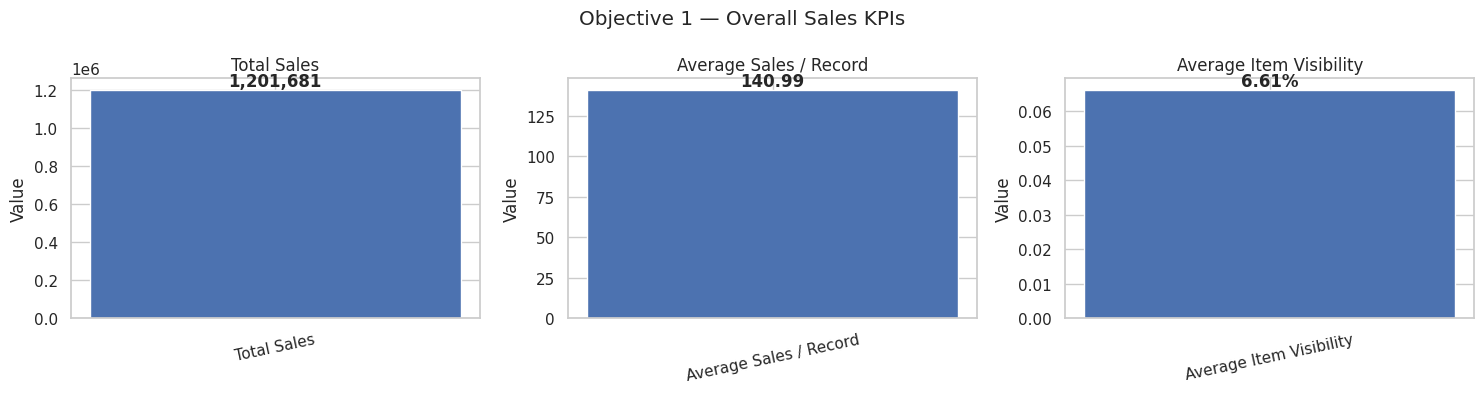

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

kpi_values = [
    (total_sales, "Total Sales", f"{total_sales:,.0f}"),
    (average_sales, "Average Sales / Record", f"{average_sales:,.2f}"),
    (average_visibility, "Average Item Visibility", f"{average_visibility:.2%}")
]

for ax, (value, title, label) in zip(axes, kpi_values):
    ax.bar([title], [value])
    ax.set_title(title)
    ax.set_ylabel("Value")
    ax.text(0, value, label, ha="center", va="bottom", fontweight="bold")
    ax.tick_params(axis="x", rotation=12)

plt.suptitle("Objective 1 — Overall Sales KPIs")
plt.tight_layout()
plt.show()

### Objective 1 — business interpretation

## 5. Objective 2 — Product Category and Sales Comparison

 Business questions
1. What percentage of total sales is contributed by the top four product categories compared with all remaining categories?
2. Which product categories generate the highest and lowest total sales?
3. How do total sales compare across outlet types?

In [ ]:
# Total sales by item category
category_sales = (
    df.groupby("Item Type")["Sales"]
      .sum()
      .sort_values(ascending=False)
)

top_four_categories = category_sales.head(4)
top_four_sales = top_four_categories.sum()
remaining_sales = total_sales - top_four_sales
top_four_pct = top_four_sales / total_sales * 100
remaining_pct = remaining_sales / total_sales * 100

print("Top four categories:")
display(top_four_categories.to_frame("Total Sales"))

print(f"Top-four sales: {top_four_sales:,.2f}")
print(f"Top-four contribution: {top_four_pct:.2f}%")
print(f"Remaining-category contribution: {remaining_pct:.2f}%")
print(f"Highest-sales category: {category_sales.idxmax()} ({category_sales.max():,.2f})")
print(f"Lowest-sales category: {category_sales.idxmin()} ({category_sales.min():,.2f})")

Top four categories:


,Total Sales
Item Type,
Fruits and Vegetables,"178,124.0810"
Snack Foods,"175,433.9224"
Household,"135,976.5254"
Frozen Foods,"118,558.8814"


Top-four sales: 608,093.41
Top-four contribution: 50.60%
Remaining-category contribution: 49.40%
Highest-sales category: Fruits and Vegetables (178,124.08)
Lowest-sales category: Seafood (9,077.87)


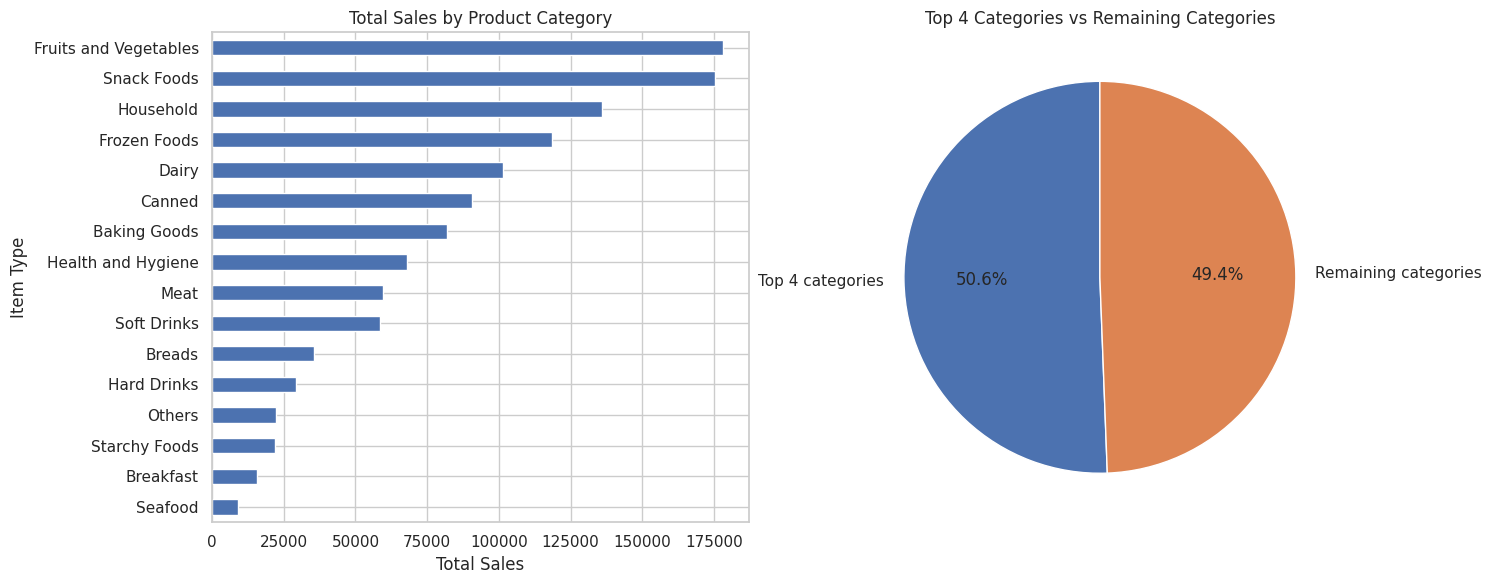

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

category_sales.sort_values().plot(kind="barh", ax=axes[0])
axes[0].set_title("Total Sales by Product Category")
axes[0].set_xlabel("Total Sales")
axes[0].set_ylabel("Item Type")

axes[1].pie(
    [top_four_sales, remaining_sales],
    labels=["Top 4 categories", "Remaining categories"],
    autopct="%1.1f%%",
    startangle=90
)
axes[1].set_title("Top 4 Categories vs Remaining Categories")

plt.tight_layout()
plt.show()

,Total Sales
Outlet Type,
Supermarket Type1,"787,549.8928"
Grocery Store,"151,939.1490"
Supermarket Type2,"131,477.7764"
Supermarket Type3,"130,714.6746"


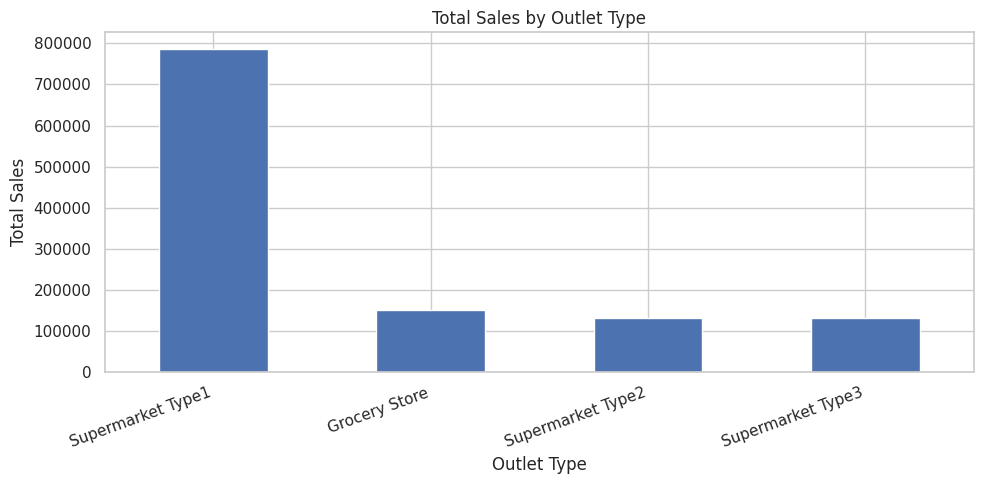

In [ ]:
# Total sales by outlet type
outlet_sales = (
    df.groupby("Outlet Type")["Sales"]
      .sum()
      .sort_values(ascending=False)
)

display(outlet_sales.to_frame("Total Sales"))

plt.figure(figsize=(10, 5))
outlet_sales.plot(kind="bar", ax=plt.gca())
plt.title("Total Sales by Outlet Type")
plt.xlabel("Outlet Type")
plt.ylabel("Total Sales")
plt.xticks(rotation=20, ha="right")
plt.tight_layout()
plt.show()

### Objective 2 — business interpretation

- The top-four share indicates how concentrated sales are among the leading categories.
- The category sales ranking identifies the strongest and weakest categories by **total** sales.
- Outlet-type totals compare the overall sales generated by each outlet format. These totals can be influenced by the number of records/outlets in each group, so compare average sales as well in Objective 4.

## 6. Objective 3 — Outlet Performance and Sales Relationships

### Business questions
1. How do sales vary across outlets for Low Fat and Regular products?
2. Is there a relationship between product visibility and sales, and what trend can be observed?
3. How do sales contributions from different product categories vary across outlet types?

Item Fat Content,Low Fat,Regular
Outlet Type,,
Grocery Store,"99,814.3670","52,124.7820"
Supermarket Type1,"507,886.3014","279,663.5914"
Supermarket Type2,"84,844.6090","46,633.1674"
Supermarket Type3,"83,774.4110","46,940.2636"


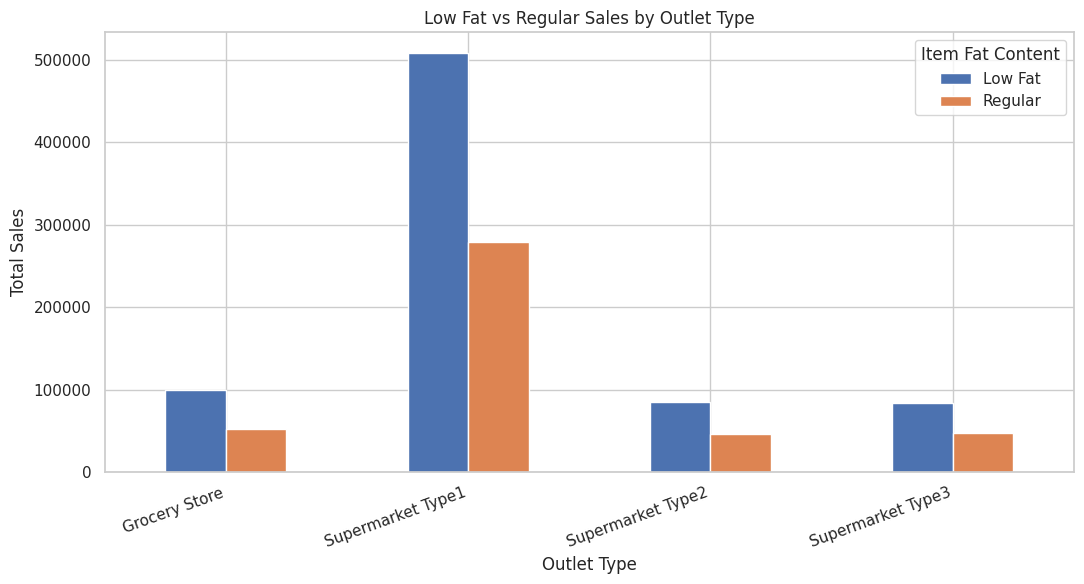

In [ ]:
# Fat-content sales by outlet type (labels were standardised during cleaning)
fat_sales_by_outlet = pd.pivot_table(
    df,
    index="Outlet Type",
    columns="Item Fat Content",
    values="Sales",
    aggfunc="sum",
    fill_value=0
)

# Keep the two requested comparison groups
fat_sales_by_outlet = fat_sales_by_outlet.reindex(
    columns=["Low Fat", "Regular"],
    fill_value=0
)

display(fat_sales_by_outlet)

fat_sales_by_outlet.plot(kind="bar", figsize=(11, 6))
plt.title("Low Fat vs Regular Sales by Outlet Type")
plt.xlabel("Outlet Type")
plt.ylabel("Total Sales")
plt.xticks(rotation=20, ha="right")
plt.legend(title="Item Fat Content")
plt.tight_layout()
plt.show()

Pearson correlation (Item Visibility vs Sales): -0.0013


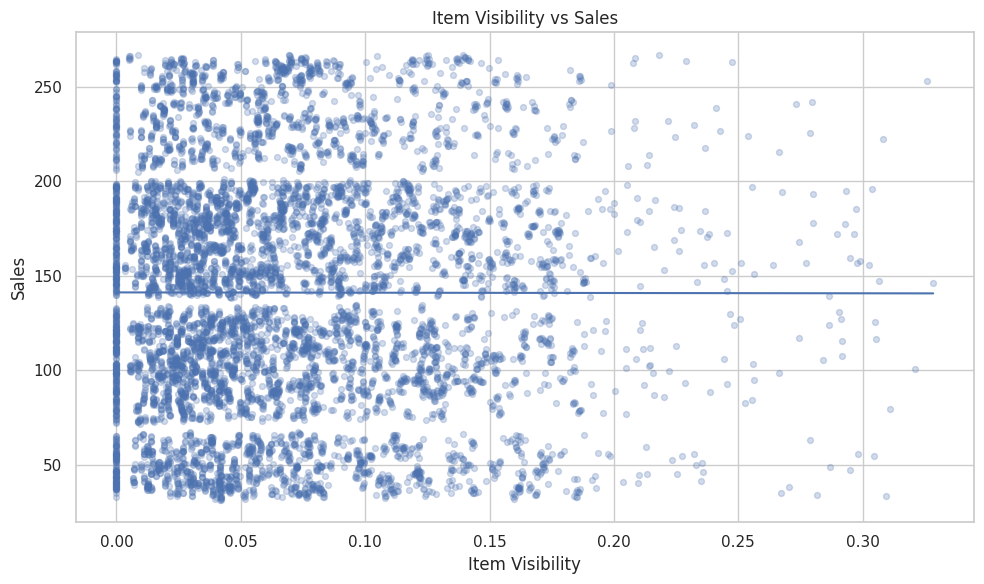

In [ ]:
# Visibility-sales correlation and scatter/regression plot
visibility_sales_corr = df["Item Visibility"].corr(df["Sales"])
print(f"Pearson correlation (Item Visibility vs Sales): {visibility_sales_corr:.4f}")

plt.figure(figsize=(10, 6))
x = df["Item Visibility"].to_numpy()
y = df["Sales"].to_numpy()
plt.scatter(x, y, alpha=0.25, s=18)
# Add a simple least-squares trend line
slope, intercept = np.polyfit(x, y, 1)
x_line = np.linspace(x.min(), x.max(), 100)
plt.plot(x_line, slope * x_line + intercept)
plt.title("Item Visibility vs Sales")
plt.xlabel("Item Visibility")
plt.ylabel("Sales")
plt.tight_layout()
plt.show()

Outlet Type,Grocery Store,Supermarket Type1,Supermarket Type2,Supermarket Type3
Item Type,,,,
Baking Goods,"10,747.2358","53,665.4614","8,594.2014","8,887.8378"
Breads,"4,832.9448","22,490.8084","3,539.4032","4,515.9634"
Breakfast,"2,793.5128","9,632.6468","1,552.6140","1,617.9230"
Canned,"10,079.8990","59,649.3094","10,852.4710","10,125.0496"
Dairy,"13,539.3398","67,179.6940","10,638.9446","9,918.4832"
Frozen Foods,"13,750.4410","79,348.3770","13,253.7174","12,206.3460"
Fruits and Vegetables,"21,423.4146","117,431.9880","18,967.2918","20,301.3866"
Hard Drinks,"2,812.5444","19,610.7566","3,609.1194","3,302.2602"
Health and Hygiene,"8,964.0234","44,050.7466","7,339.9238","7,671.1450"


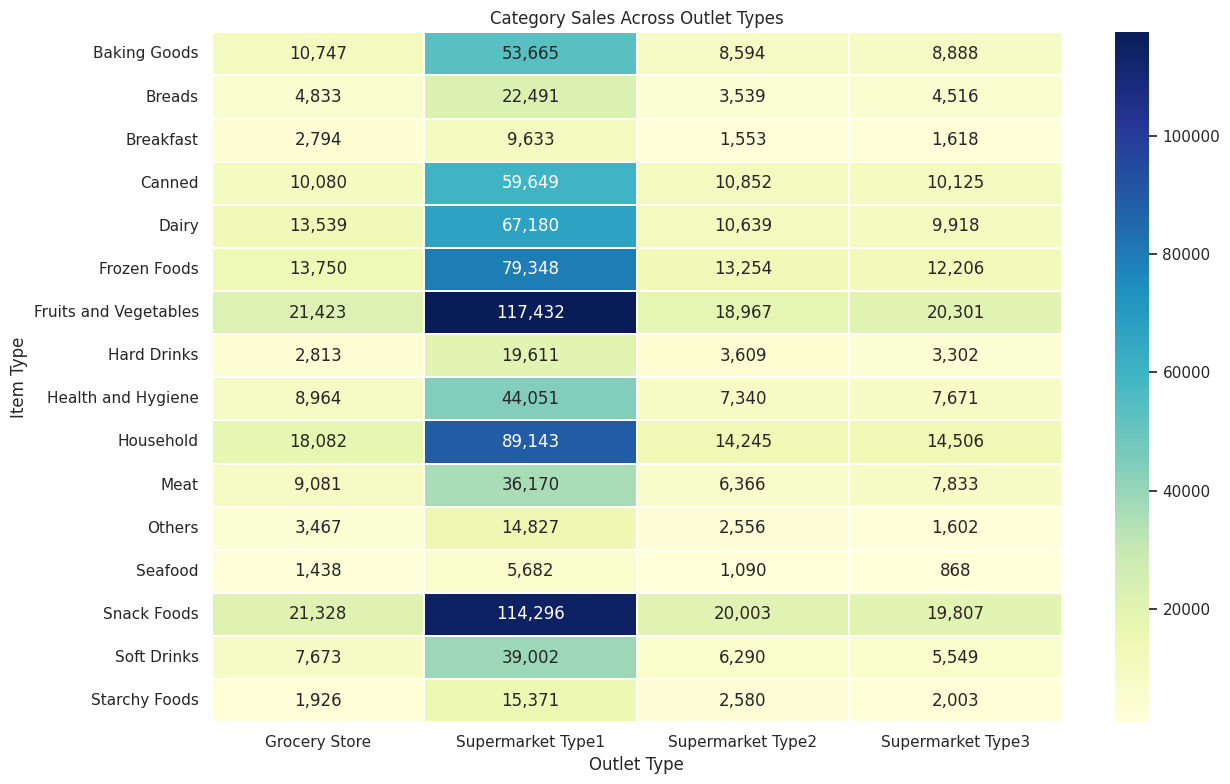

In [ ]:
# Category total sales by outlet type
category_outlet_sales = pd.pivot_table(
    df,
    index="Item Type",
    columns="Outlet Type",
    values="Sales",
    aggfunc="sum",
    fill_value=0
)

display(category_outlet_sales)

plt.figure(figsize=(13, 8))
sns.heatmap(
    category_outlet_sales,
    cmap="YlGnBu",
    annot=True,
    fmt=",.0f",
    linewidths=0.3
)
plt.title("Category Sales Across Outlet Types")
plt.xlabel("Outlet Type")
plt.ylabel("Item Type")
plt.tight_layout()
plt.show()

Outlet Type,Grocery Store,Supermarket Type1,Supermarket Type2,Supermarket Type3
Item Type,,,,
Baking Goods,7.0700,6.8100,6.5400,6.8000
Breads,3.1800,2.8600,2.6900,3.4500
Breakfast,1.8400,1.2200,1.1800,1.2400
Canned,6.6300,7.5700,8.2500,7.7500
Dairy,8.9100,8.5300,8.0900,7.5900
Frozen Foods,9.0500,10.0800,10.0800,9.3400
Fruits and Vegetables,14.1000,14.9100,14.4300,15.5300
Hard Drinks,1.8500,2.4900,2.7500,2.5300
Health and Hygiene,5.9000,5.5900,5.5800,5.8700


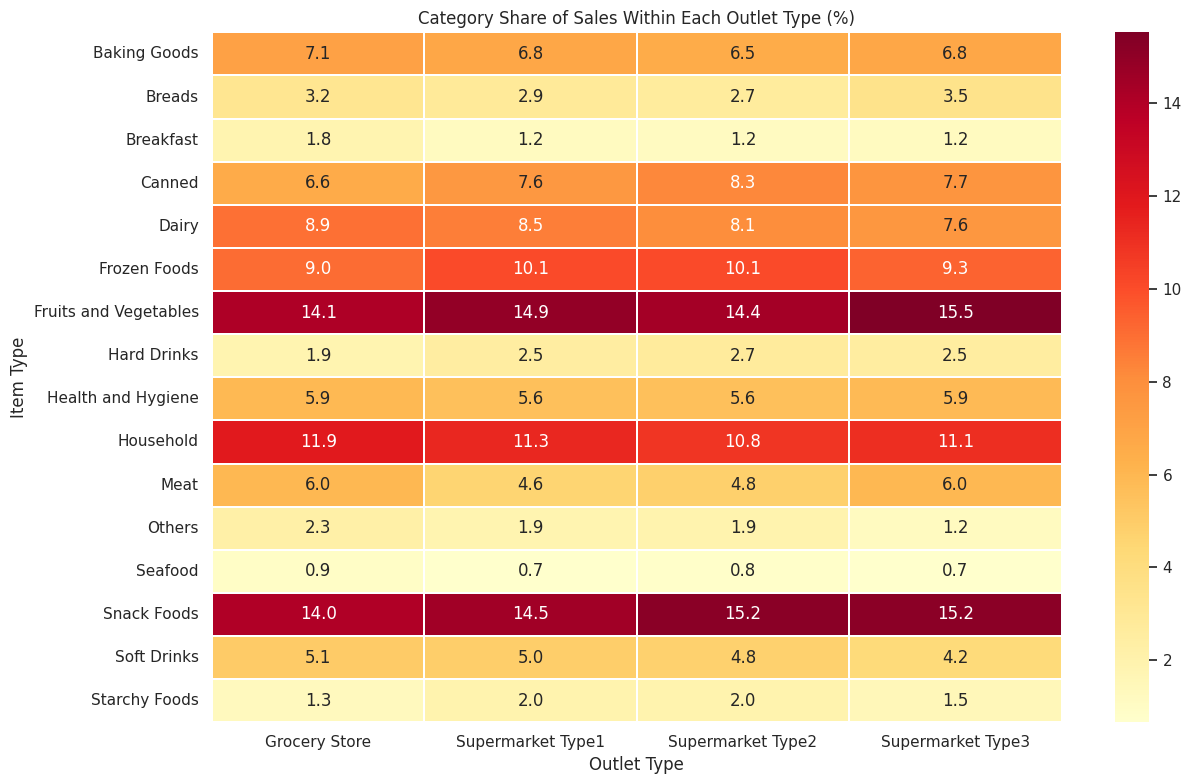

In [ ]:
# Percentage contribution within each outlet type
# Each outlet-type column sums to 100%, enabling fairer mix comparisons.
category_outlet_pct = (
    category_outlet_sales
    .div(category_outlet_sales.sum(axis=0), axis=1)
    .mul(100)
)

display(category_outlet_pct.round(2))

plt.figure(figsize=(13, 8))
sns.heatmap(
    category_outlet_pct,
    cmap="YlOrRd",
    annot=True,
    fmt=".1f",
    linewidths=0.3
)
plt.title("Category Share of Sales Within Each Outlet Type (%)")
plt.xlabel("Outlet Type")
plt.ylabel("Item Type")
plt.tight_layout()
plt.show()

### Objective 3 — business interpretation

- The grouped chart compares Low Fat and Regular sales within each outlet type. It uses the cleaned labels so that `LF` and `low fat` are not incorrectly treated as separate groups.
- Pearson correlation measures the **linear** relationship between visibility and sales. A value close to zero means little linear association in this dataset; it does not prove that visibility can never affect sales.
- The first heatmap compares category sales totals. The percentage heatmap compares category mix within each outlet type, where each outlet-type column totals 100%.

## 7. Objective 4 — Statistical Analysis of Sales

### Business questions
1. What are the average, median, minimum, and maximum sales values?
2. How much variation exists in sales across product records?
3. Which records have unusually high or low sales compared with most records?
4. How does average sales performance differ across product categories, outlet types, and outlet locations?

In [ ]:
sales_stats = df["Sales"].agg(
    ["mean", "median", "min", "max", "std", "var"]
).rename({
    "mean": "Mean",
    "median": "Median",
    "min": "Minimum",
    "max": "Maximum",
    "std": "Standard deviation",
    "var": "Variance"
})

display(sales_stats.to_frame("Sales value").style.format("{:,.4f}"))

print(f"Number of sales records: {df['Sales'].count():,}")
print(f"Mean sales: {df['Sales'].mean():,.2f}")
print(f"Median sales: {df['Sales'].median():,.2f}")
print(f"Minimum sales: {df['Sales'].min():,.2f}")
print(f"Maximum sales: {df['Sales'].max():,.2f}")
print(f"Standard deviation: {df['Sales'].std():,.2f}")
print(f"Variance: {df['Sales'].var():,.2f}")

,Sales value
Mean,140.9928
Median,143.0128
Minimum,31.2900
Maximum,266.8884
Standard deviation,62.2751
Variance,"3,878.1839"


Number of sales records: 8,523
Mean sales: 140.99
Median sales: 143.01
Minimum sales: 31.29
Maximum sales: 266.89
Standard deviation: 62.28
Variance: 3,878.18


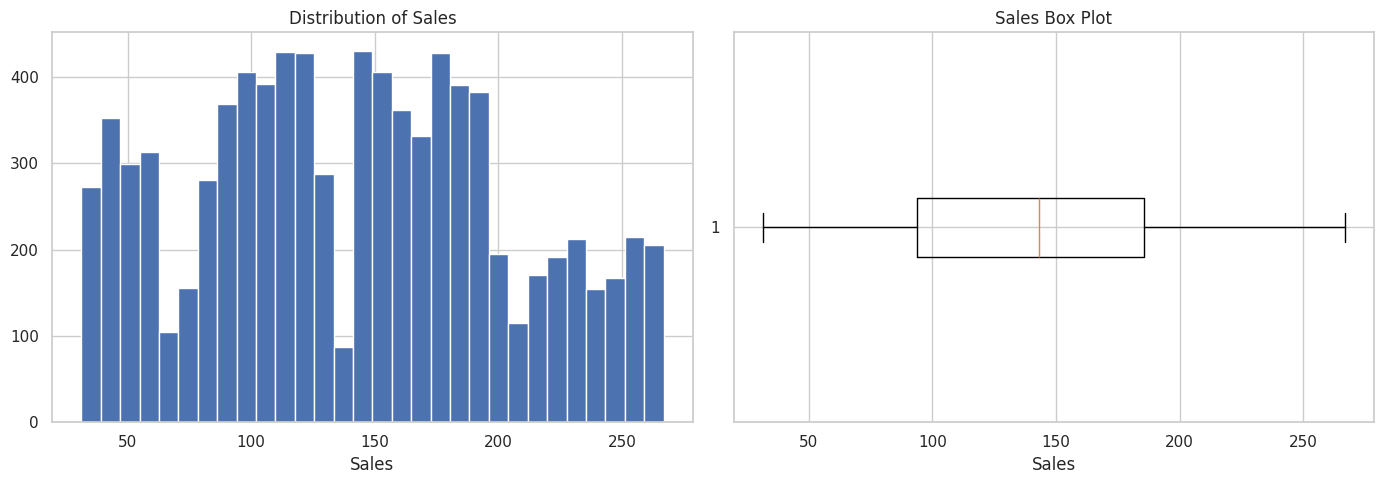

In [ ]:
# Sales distribution
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].hist(df["Sales"], bins=30)
axes[0].set_title("Distribution of Sales")
axes[0].set_xlabel("Sales")

axes[1].boxplot(df["Sales"], vert=False)
axes[1].set_title("Sales Box Plot")
axes[1].set_xlabel("Sales")

plt.tight_layout()
plt.show()

### Unusual sales records — IQR method

The interquartile range (IQR) method defines potential outliers as values below Q1 − 1.5 × IQR or above Q3 + 1.5 × IQR. The records are flagged for investigation; they should not automatically be deleted.

In [ ]:
q1 = df["Sales"].quantile(0.25)
q3 = df["Sales"].quantile(0.75)
iqr = q3 - q1

lower_bound = q1 - 1.5 * iqr
upper_bound = q3 + 1.5 * iqr

sales_outliers = df.loc[
    (df["Sales"] < lower_bound) | (df["Sales"] > upper_bound)
].copy()

print(f"Q1: {q1:,.4f}")
print(f"Q3: {q3:,.4f}")
print(f"IQR: {iqr:,.4f}")
print(f"Lower outlier boundary: {lower_bound:,.4f}")
print(f"Upper outlier boundary: {upper_bound:,.4f}")
print(f"Potential outlier records: {len(sales_outliers):,}")

display(sales_outliers.head(20))

Q1: 93.8265
Q3: 185.6437
IQR: 91.8172
Lower outlier boundary: -43.8993
Upper outlier boundary: 323.3695
Potential outlier records: 0


,Item Fat Content,Item Identifier,Item Type,Outlet Establishment Year,Outlet Identifier,Outlet Location Type,Outlet Size,Outlet Type,Item Visibility,Item Weight,Sales,Rating


If the IQR method returns no records, report that result accurately. To help management inspect the tails of the distribution anyway, the next cell separately lists the bottom and top 5% of sales. These are percentile groups, **not statistical outliers**.

In [ ]:
low_5pct_records = df.loc[
    df["Sales"] <= df["Sales"].quantile(0.05)
].sort_values("Sales")

high_5pct_records = df.loc[
    df["Sales"] >= df["Sales"].quantile(0.95)
].sort_values("Sales", ascending=False)

print("Bottom 5% of sales records:")
display(low_5pct_records.head(10))

print("Top 5% of sales records:")
display(high_5pct_records.head(10))

Bottom 5% of sales records:


,Item Fat Content,Item Identifier,Item Type,Outlet Establishment Year,Outlet Identifier,Outlet Location Type,Outlet Size,Outlet Type,Item Visibility,Item Weight,Sales,Rating
5872,Low Fat,DRK12,Soft Drinks,2018,OUT027,Tier 3,Medium,Supermarket Type3,0.0417,12.6000,31.2900,4.0000
7880,Low Fat,DRK12,Soft Drinks,2014,OUT013,Tier 3,High,Supermarket Type1,0.0419,9.5000,31.4900,4.0000
8136,Low Fat,DRK12,Soft Drinks,2022,OUT018,Tier 3,Medium,Supermarket Type2,0.0421,9.5000,31.8900,4.0000
7753,Low Fat,FDX59,Breads,2014,OUT013,Tier 3,High,Supermarket Type1,0.0516,10.1950,31.9558,4.0000
8300,Low Fat,FDG40,Frozen Foods,2018,OUT027,Tier 3,Medium,Supermarket Type3,0.0396,12.6000,31.9558,4.0000
7548,Regular,FDV28,Frozen Foods,2017,OUT035,Tier 2,Small,Supermarket Type1,0.1597,16.1000,32.0558,4.0000
1541,Low Fat,DRK12,Soft Drinks,2020,OUT017,Tier 2,Medium,Supermarket Type1,0.0421,9.5000,32.0900,4.3000
5098,Regular,FDU21,Snack Foods,2014,OUT013,Tier 3,High,Supermarket Type1,0.0767,11.8000,32.3558,3.3000
127,Low Fat,NCO06,Household,2016,OUT046,Tier 1,Small,Supermarket Type1,0.1080,19.2500,32.4558,5.0000
2729,Low Fat,DRK12,Soft Drinks,2012,OUT049,Tier 1,Medium,Supermarket Type1,0.0420,9.5000,32.4900,4.1000


Top 5% of sales records:


,Item Fat Content,Item Identifier,Item Type,Outlet Establishment Year,Outlet Identifier,Outlet Location Type,Outlet Size,Outlet Type,Item Visibility,Item Weight,Sales,Rating
183,Low Fat,FDS13,Canned,2020,OUT017,Tier 2,Small,Supermarket Type1,0.1252,6.4650,266.8884,5.0000
3398,Regular,FDR25,Canned,2016,OUT046,Tier 1,Small,Supermarket Type1,0.1395,17.0000,266.8884,4.0000
1775,Low Fat,NCS29,Health and Hygiene,2014,OUT013,Tier 3,High,Supermarket Type1,0.0695,9.0000,266.6884,4.3000
559,Low Fat,FDK51,Dairy,2011,OUT010,Tier 3,Medium,Grocery Store,0.0088,19.8500,266.6884,4.7000
3563,Low Fat,NCS29,Health and Hygiene,2017,OUT035,Tier 2,Small,Supermarket Type1,0.0695,9.0000,266.5884,4.0000
5419,Low Fat,FDS13,Canned,2018,OUT019,Tier 1,Small,Grocery Store,0.2180,12.6000,266.5884,2.9000
2720,Low Fat,NCS29,Health and Hygiene,2012,OUT049,Tier 1,Medium,Supermarket Type1,0.0697,9.0000,266.2884,4.1000
4977,Low Fat,FDS13,Canned,2014,OUT013,Tier 3,High,Supermarket Type1,0.1244,6.4650,266.1884,3.4000
6202,Low Fat,FDK51,Dairy,2012,OUT049,Tier 1,Medium,Supermarket Type1,0.0052,19.8500,266.1884,4.0000
2131,Low Fat,NCM05,Health and Hygiene,2018,OUT019,Tier 1,Small,Grocery Store,0.1048,12.6000,266.0226,4.2000


### Average sales by category, outlet type, and outlet location

In [ ]:
average_sales_by_category = (
    df.groupby("Item Type")["Sales"]
      .mean()
      .sort_values(ascending=False)
)

average_sales_by_outlet_type = (
    df.groupby("Outlet Type")["Sales"]
      .mean()
      .sort_values(ascending=False)
)

average_sales_by_location = (
    df.groupby("Outlet Location Type")["Sales"]
      .mean()
      .sort_values(ascending=False)
)

print("Average sales by product category:")
display(average_sales_by_category.to_frame("Average Sales"))

print("Average sales by outlet type:")
display(average_sales_by_outlet_type.to_frame("Average Sales"))

print("Average sales by outlet location:")
display(average_sales_by_location.to_frame("Average Sales"))

Average sales by product category:


,Average Sales
Item Type,
Household,149.4248
Dairy,148.4992
Starchy Foods,147.8380
Snack Foods,146.1949
Fruits and Vegetables,144.5812
Seafood,141.8417
Breakfast,141.7882
Breads,140.9527
Meat,139.8820


Average sales by outlet type:


,Average Sales
Outlet Type,
Supermarket Type2,141.6786
Supermarket Type1,141.2139
Grocery Store,140.2947
Supermarket Type3,139.8018


Average sales by outlet location:


,Average Sales
Outlet Location Type,
Tier 2,141.1672
Tier 3,140.9352
Tier 1,140.8701


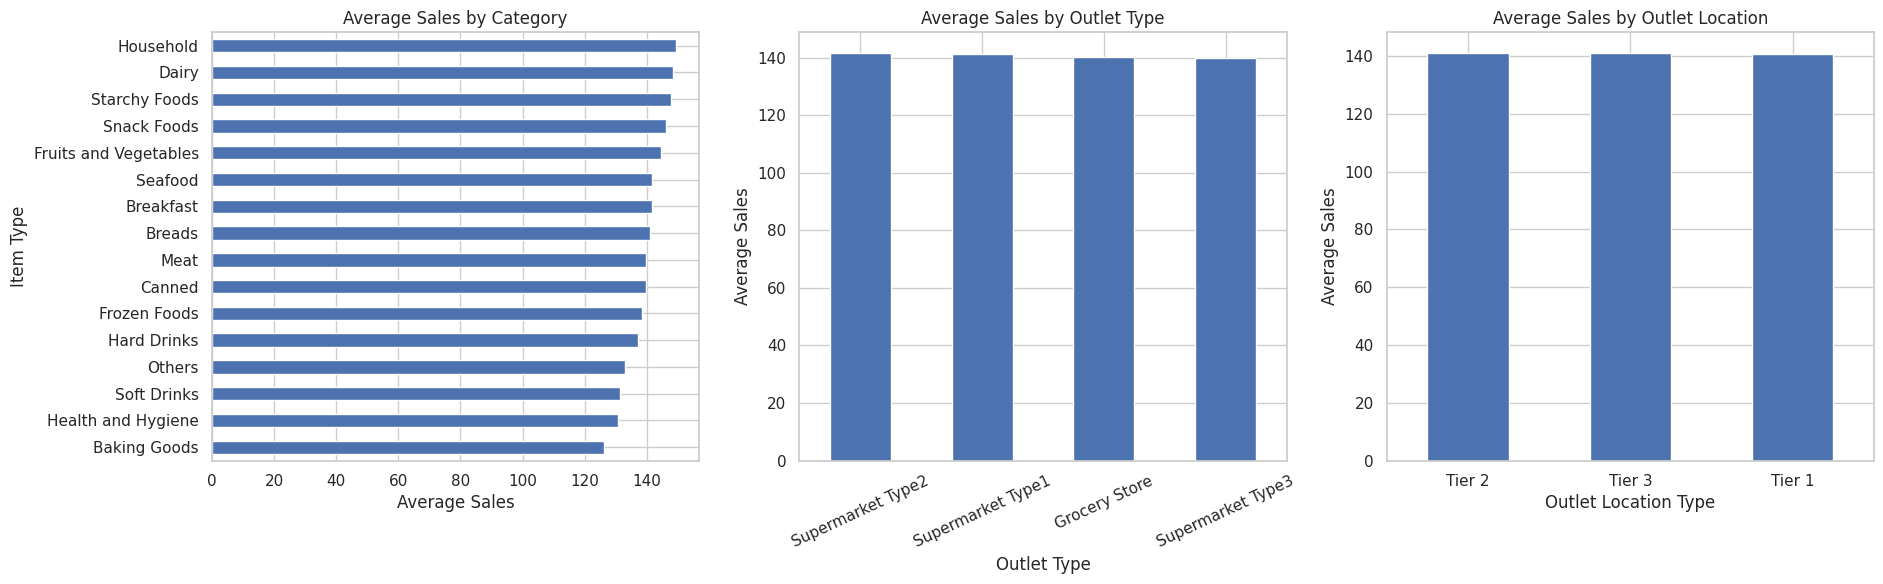

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(19, 6))

average_sales_by_category.sort_values().plot(kind="barh", ax=axes[0])
axes[0].set_title("Average Sales by Category")
axes[0].set_xlabel("Average Sales")

average_sales_by_outlet_type.plot(kind="bar", ax=axes[1])
axes[1].set_title("Average Sales by Outlet Type")
axes[1].set_ylabel("Average Sales")
axes[1].tick_params(axis="x", rotation=25)

average_sales_by_location.plot(kind="bar", ax=axes[2])
axes[2].set_title("Average Sales by Outlet Location")
axes[2].set_ylabel("Average Sales")
axes[2].tick_params(axis="x", rotation=0)

plt.tight_layout()
plt.show()

### Objective 4 — business interpretation

- Mean and median describe the centre of the sales distribution.
- Standard deviation and variance describe how spread out the sales values are.
- IQR flags potential unusually low or high records for review.
- Average sales by category, outlet type, and location allows comparison of a typical record in each group. These averages should be interpreted alongside group sizes and total sales.

## 8. Consolidated business summary

This section creates a compact set of metrics and ranked tables that can be used in a management report or dashboard.

In [ ]:
business_summary = pd.DataFrame({
    "Metric": [
        "Number of sales records",
        "Total sales",
        "Average sales per record",
        "Average item visibility",
        "Median sales",
        "Minimum sales",
        "Maximum sales",
        "Sales standard deviation",
        "Top 4 category contribution (%)",
        "Visibility-sales Pearson correlation",
        "IQR potential outlier count"
    ],
    "Value": [
        len(df),
        total_sales,
        average_sales,
        average_visibility,
        df["Sales"].median(),
        df["Sales"].min(),
        df["Sales"].max(),
        df["Sales"].std(),
        top_four_pct,
        visibility_sales_corr,
        len(sales_outliers)
    ]
})

display(business_summary)
print("Highest total-sales category:", category_sales.idxmax())
print("Lowest total-sales category:", category_sales.idxmin())
print("Highest total-sales outlet type:", outlet_sales.idxmax())

,Metric,Value
0,Number of sales records,"8,523.0000"
1,Total sales,"1,201,681.4928"
2,Average sales per record,140.9928
3,Average item visibility,0.0661
4,Median sales,143.0128
5,Minimum sales,31.2900
6,Maximum sales,266.8884
7,Sales standard deviation,62.2751
8,Top 4 category contribution (%),50.6035
9,Visibility-sales Pearson correlation,-0.0013


Highest total-sales category: Fruits and Vegetables
Lowest total-sales category: Seafood
Highest total-sales outlet type: Supermarket Type1


## 9. Business findings


### Findings
- Total sales are approximately **1,201,681.49** across **8,523** records.
- Average sales per record are approximately **140.99**.
- Average item visibility is approximately **0.0661** (about **6.61%**).
- The four highest-sales categories contribute approximately **50.60%** of total sales.
- **Fruits and Vegetables** is the highest category by total sales; **Seafood** is the lowest.
- **Supermarket Type1** has the highest total sales among outlet types.
- The visibility-sales Pearson correlation is approximately **−0.0013**, indicating virtually no linear association in this dataset.
- Sales standard deviation is approximately **62.28**. The IQR method should be used to identify potential outliers; the result is displayed above.


## 10. Export analysis tables to Excel

The following cell creates a workbook with separate sheets for the KPI summary, category sales, outlet sales, fat-content comparison, category-by-outlet totals, category contribution percentages, statistical measures, average sales comparisons, and any IQR-flagged records.

In [ ]:
output_path = Path("Sapphire_IQ_Supermarket_Analysis_Results.xlsx")

with pd.ExcelWriter(output_path, engine="openpyxl") as writer:
    business_summary.to_excel(writer, sheet_name="Business Summary", index=False)
    category_sales.rename("Total Sales").to_frame().to_excel(writer, sheet_name="Category Sales")
    outlet_sales.rename("Total Sales").to_frame().to_excel(writer, sheet_name="Outlet Sales")
    fat_sales_by_outlet.to_excel(writer, sheet_name="Fat Content by Outlet")
    category_outlet_sales.to_excel(writer, sheet_name="Category Outlet Sales")
    category_outlet_pct.to_excel(writer, sheet_name="Category Outlet Share")
    sales_stats.rename("Value").to_frame().to_excel(writer, sheet_name="Sales Statistics")
    average_sales_by_category.rename("Average Sales").to_frame().to_excel(writer, sheet_name="Avg by Category")
    average_sales_by_outlet_type.rename("Average Sales").to_frame().to_excel(writer, sheet_name="Avg by Outlet")
    average_sales_by_location.rename("Average Sales").to_frame().to_excel(writer, sheet_name="Avg by Location")
    sales_outliers.to_excel(writer, sheet_name="IQR Outliers", index=False)

print(f"Excel analysis workbook saved to: {output_path.resolve()}")

Excel analysis workbook saved to: /mnt/data/Sapphire_IQ_Supermarket_Analysis_Results.xlsx


#